# Feature Scaling: Normalization (Min-Max Scaling)

**Normalization** (specifically **Min-Max Scaling**) scales numerical features into a fixed, bounded range—most commonly between $0$ and $1$.

For each feature value $x$, Min-Max scaling computes:

$$x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

where $x_{\min}$ and $x_{\max}$ are the minimum and maximum values of the feature.

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand the mathematics and use cases for **Min-Max Scaling** vs. **Standardisation**.
2. Recognize the primary vulnerability of Min-Max scaling: **extreme sensitivity to outliers**.
3. Understand what happens when **test set observations exceed training bounds** ($x_{\text{test}} < 0$ or $> 1$).
4. Implement Min-Max scaling using scikit-learn's `MinMaxScaler` with pandas DataFrame output.
5. Prevent data leakage by fitting parameters strictly on the training set.

---
## 1. When to Use Min-Max Scaling vs. Standardisation

| Consideration | Standardisation (Z-Score) | Min-Max Scaling |
| :--- | :--- | :--- |
| **Output Range** | Unbounded (typically $\approx [-3, 3]$) | **Strictly bounded** (default: $[0, 1]$) |
| **Outlier Sensitivity** | Moderate (no hard upper/lower compression) | **High** (outliers compress typical values into a narrow range) |
| **Preserves Zero / Sparsity** | No (shifts zero to $-\mu / \sigma$) | Optional (`feature_range=(0, 1)` maintains non-negativity) |
| **Best Used For** | General ML: Linear models, Logistic Regression, SVM, KNN, PCA | Neural networks with bounded activations, image pixel intensities $[0, 1]$, algorithms requiring strictly non-negative features |

---

### ⚠️ Critical Test Set Consideration
If an observation in the **test set** has a value smaller than the training minimum or larger than the training maximum:
- $x_{\text{scaled}}$ for that test point will be **$< 0$** or **$> 1$**.
- This is mathematically correct: the test set is evaluated against the *training baseline*. We do not recompute min and max on the test set, because doing so would cause **data leakage**!

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Matplotlib styling
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading Data & Splitting Train/Test Sets

We use the California Housing dataset. We split into training and test sets **before** fitting the scaler to prevent data leakage.

In [2]:
# Load dataset
housing = fetch_california_housing(as_frame=True)
data = housing.frame

# Separate predictors and target
X = data.drop("MedHouseVal", axis=1)
y = data["MedHouseVal"]

# Train/Test Split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (14448, 8)
X_test shape:  (6192, 8)


In [3]:
# Inspect original minimum and maximum values on training set
range_table = pd.DataFrame({
    'Min (X_train)': X_train.min(),
    'Max (X_train)': X_train.max(),
    'Range (Max - Min)': X_train.max() - X_train.min()
})

range_table.round(2)

,Min (X_train),Max (X_train),Range (Max - Min)
MedInc,0.50,15.00,14.50
HouseAge,1.00,52.00,51.00
AveRooms,0.85,132.53,131.69
AveBedrms,0.33,34.07,33.73
Population,3.00,35682.00,35679.00
AveOccup,0.75,599.71,598.96
Latitude,32.54,41.95,9.41
Longitude,-124.35,-114.31,10.04


---
## 3. Implementing Min-Max Scaling with Scikit-Learn

We use scikit-learn's `MinMaxScaler(feature_range=(0, 1))`.

Using `.set_output(transform="pandas")` ensures the output remains a clean pandas DataFrame.

In [4]:
# Initialize MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.set_output(transform="pandas")

# Fit on training set ONLY (learns min and max per feature)
scaler.fit(X_train)

# Transform both train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

X_train_scaled.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
1989,0.101730,1.000000,0.014837,0.010870,0.005325,0.006803,0.445271,0.454183
256,0.121412,0.823529,0.021455,0.025221,0.023347,0.003787,0.555792,0.213147
7887,0.399932,0.313725,0.042767,0.022369,0.038790,0.005110,0.141339,0.628486
4581,0.084137,0.313725,0.012696,0.025573,0.085428,0.003842,0.161530,0.604582
1993,0.118667,0.960784,0.028679,0.024556,0.016901,0.004806,0.445271,0.452191


---
## 4. Inspecting the Learned Parameters

The scaler stores:
- `scaler.data_min_`: The minimum value per feature learned from `X_train`.
- `scaler.data_max_`: The maximum value per feature learned from `X_train`.
- `scaler.data_range_`: The range ($x_{\max} - x_{\min}$) learned from `X_train`.

In [5]:
# Summary of learned scaler parameters
learned_params = pd.DataFrame({
    'Feature': X_train.columns,
    'Learned Min': scaler.data_min_,
    'Learned Max': scaler.data_max_,
    'Learned Range': scaler.data_range_
}).set_index('Feature')

learned_params.round(3)

,Learned Min,Learned Max,Learned Range
Feature,,,
MedInc,0.500,15.000,14.500
HouseAge,1.000,52.000,51.000
AveRooms,0.846,132.533,131.687
AveBedrms,0.333,34.067,33.733
Population,3.000,35682.000,35679.000
AveOccup,0.750,599.714,598.964
Latitude,32.540,41.950,9.410
Longitude,-124.350,-114.310,10.040


---
## 5. Statistical Verification: Training Set vs. Test Set

Let's check the minimum and maximum of the scaled datasets.

In [6]:
# Verification on X_train_scaled (must be exactly 0.0 and 1.0)
train_scaled_summary = pd.DataFrame({
    'Min (should be 0.0)': X_train_scaled.min(),
    'Max (should be 1.0)': X_train_scaled.max()
})

train_scaled_summary.round(4)

,Min (should be 0.0),Max (should be 1.0)
MedInc,0.0,1.0
HouseAge,0.0,1.0
AveRooms,0.0,1.0
AveBedrms,0.0,1.0
Population,0.0,1.0
AveOccup,0.0,1.0
Latitude,0.0,1.0
Longitude,0.0,1.0


Now let's examine `X_test_scaled`: notice that some values may be slightly below 0 or above 1 because the test set contains points outside the training boundaries.

In [7]:
# Verification on X_test_scaled
test_scaled_summary = pd.DataFrame({
    'X_test Min': X_test_scaled.min(),
    'X_test Max': X_test_scaled.max()
})

test_scaled_summary.round(4)

,X_test Min,X_test Max
MedInc,0.0000,1.0000
HouseAge,0.0000,1.0000
AveRooms,0.0047,1.0712
AveBedrms,0.0049,0.7501
Population,0.0001,0.4569
AveOccup,-0.0001,2.0746
Latitude,0.0021,1.0000
Longitude,0.0050,0.9821


---
## 6. Visualizing the Impact: Before vs. After MinMax Scaling

Let's plot the distributions of `MedInc` and `HouseAge` before and after scaling.

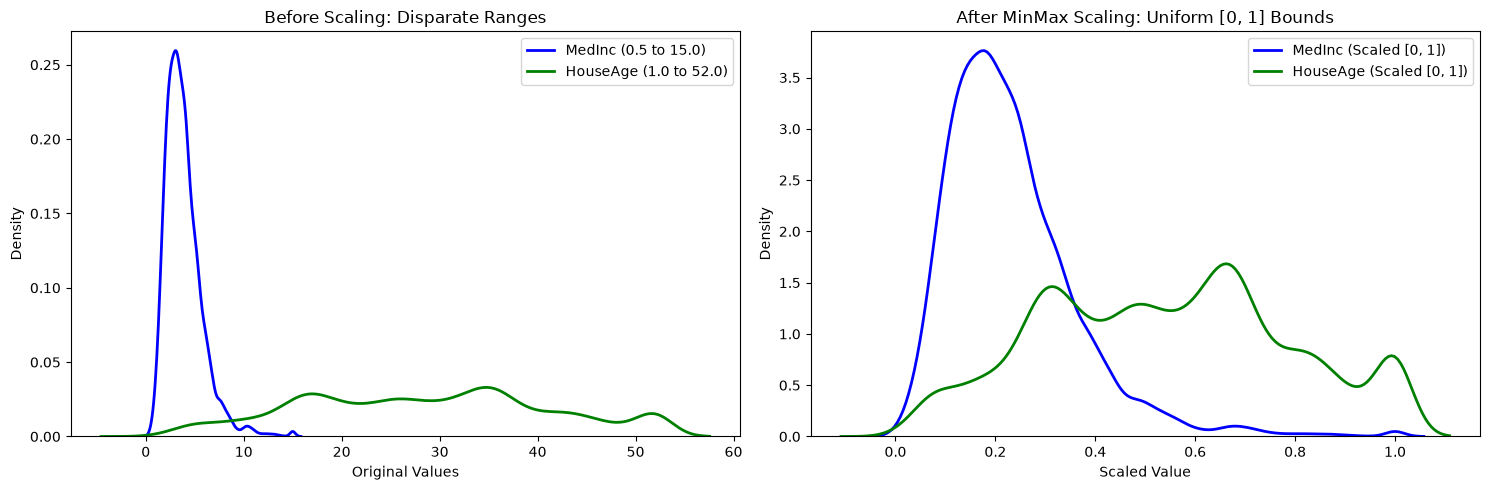

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Before scaling
sns.kdeplot(X_train['MedInc'], ax=ax1, color='blue', label='MedInc (0.5 to 15.0)', lw=2)
sns.kdeplot(X_train['HouseAge'], ax=ax1, color='green', label='HouseAge (1.0 to 52.0)', lw=2)
ax1.set_title('Before Scaling: Disparate Ranges')
ax1.set_xlabel('Original Values')
ax1.legend()

# After scaling: Both bounded within [0, 1]
sns.kdeplot(X_train_scaled['MedInc'], ax=ax2, color='blue', label='MedInc (Scaled [0, 1])', lw=2)
sns.kdeplot(X_train_scaled['HouseAge'], ax=ax2, color='green', label='HouseAge (Scaled [0, 1])', lw=2)
ax2.set_title('After MinMax Scaling: Uniform [0, 1] Bounds')
ax2.set_xlabel('Scaled Value')
ax2.legend()

plt.tight_layout()
plt.show()

### Key Takeaways:
1. **Preserved Shape**: Notice how the shape of each curve (including peaks and skewness) is preserved. Only the horizontal scale has been compressed into $[0, 1]$.
2. **Outlier Impact**: If a feature has an extreme outlier (e.g., $x_{\max} = 10,000$ when most values are around $10$), $99\%$ of observations will be compressed between $0.0$ and $0.001$. In such situations, **Standardisation** or **RobustScaler** is vastly preferred.

---
## 7. Summary & Best Practices Checklist

| Consideration | Recommendation |
| :--- | :--- |
| **When to Use** | When features must strictly lie in a bounded interval (e.g. image processing, neural net inputs, non-negative algorithms). |
| **Outlier Risk** | If significant outliers exist, Min-Max scaling compresses inliers into a tiny sub-range. Standardisation is safer under outliers. |
| **Test Set Values** | Transformed test observations may fall outside $[0, 1]$ if test points exceed training extremes. This is expected and prevents leakage. |
| **Pipeline Integration** | Use `MinMaxScaler().set_output(transform="pandas")` within a scikit-learn `Pipeline`. |
